In [1]:
import pandas as pd

LABEL_CSV = r"C:/Users/sanja/Desktop/EEG_Project/EEG/eeg/derivatives/labels.csv"
df = pd.read_csv(LABEL_CSV)
print(df.head())
print("\nColumns in your CSV:", list(df.columns))


   subject label
0  sub-001    AD
1  sub-002    AD
2  sub-003    AD
3  sub-004    AD
4  sub-005    AD

Columns in your CSV: ['subject', 'label']


In [2]:
import os
BIDS_ROOT = r"C:/Users/sanja/Desktop/EEG_Project/EEG/eeg"

for subj_id in ['001','002','003']:
    subj_path = os.path.join(BIDS_ROOT, f"sub-{subj_id}", "eeg")
    if os.path.exists(subj_path):
        print(f"✅ Found folder: {subj_path}")
        print("Files:", os.listdir(subj_path))
    else:
        print(f"❌ Missing folder for sub-{subj_id}")


✅ Found folder: C:/Users/sanja/Desktop/EEG_Project/EEG/eeg\sub-001\eeg
Files: ['sub-001_task-eyesclosed_channels.tsv', 'sub-001_task-eyesclosed_eeg.json', 'sub-001_task-eyesclosed_eeg.set']
✅ Found folder: C:/Users/sanja/Desktop/EEG_Project/EEG/eeg\sub-002\eeg
Files: ['sub-002_task-eyesclosed_channels.tsv', 'sub-002_task-eyesclosed_eeg.json', 'sub-002_task-eyesclosed_eeg.set']
✅ Found folder: C:/Users/sanja/Desktop/EEG_Project/EEG/eeg\sub-003\eeg
Files: ['sub-003_task-eyesclosed_channels.tsv', 'sub-003_task-eyesclosed_eeg.json', 'sub-003_task-eyesclosed_eeg.set']


In [3]:
import mne, os

BIDS_ROOT = r"C:/Users/sanja/Desktop/EEG_Project/EEG/eeg"
subject = "001"
eeg_file = os.path.join(BIDS_ROOT, f"sub-{subject}", "eeg", f"sub-{subject}_task-eyesclosed_eeg.set")

print("🔍 Looking for:", eeg_file)
raw = mne.io.read_raw_eeglab(eeg_file, preload=True, verbose=True)
print("✅ Loaded:", raw)


🔍 Looking for: C:/Users/sanja/Desktop/EEG_Project/EEG/eeg\sub-001\eeg\sub-001_task-eyesclosed_eeg.set
✅ Loaded: <RawEEGLAB | sub-001_task-eyesclosed_eeg.set, 19 x 299900 (599.8 s), ~43.5 MiB, data loaded>


In [4]:
import os
import mne
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

# === CONFIG ===
BIDS_ROOT = r"C:/Users/sanja/Desktop/EEG_Project/EEG/eeg"
LABEL_CSV = r"C:/Users/sanja/Desktop/EEG_Project/EEG/eeg/derivatives/labels.csv"
N_SUBJECTS = 65

# === LOAD LABELS ===
labels_df = pd.read_csv(LABEL_CSV)
labels_df = labels_df[labels_df['label'].isin(['AD', 'CN', 'HC'])].head(N_SUBJECTS)
label_map = {'AD': 0, 'CN': 1, 'HC': 1}
X, y = [], []

print(f"Found {len(labels_df)} subjects in label file")

# === LOOP THROUGH SUBJECTS ===
for idx, row in labels_df.iterrows():
    subj_raw = str(row['subject']).strip()   # e.g. "sub-001" or "001"
    diagnosis = row['label']
    label = label_map[diagnosis]

    # ✅ Ensure we never double “sub-”
    if subj_raw.startswith("sub-"):
        subj_folder = subj_raw
    else:
        subj_folder = f"sub-{subj_raw.zfill(3)}"

    subj_path = os.path.join(BIDS_ROOT, subj_folder, "eeg")

    if not os.path.exists(subj_path):
        print(f"⚠️ Folder not found for {subj_folder}: {subj_path}")
        continue

    # Find EEG file (.set)
    eeg_file = None
    for file in os.listdir(subj_path):
        if file.endswith(".set"):
            eeg_file = os.path.join(subj_path, file)
            break

    if eeg_file is None:
        print(f"⚠️ No .set EEG file found in {subj_path}")
        continue

    print(f"✅ Loading {os.path.basename(eeg_file)} from {subj_folder}")

    # === Load EEG using MNE ===
    raw = mne.io.read_raw_eeglab(eeg_file, preload=True, verbose=False)
    data = raw.get_data()
    sfreq = int(raw.info['sfreq'])
    win_size = 2 * sfreq  # 2-second windows

    n_segments = data.shape[1] // win_size
    for i in range(n_segments):
        seg = data[:, i*win_size:(i+1)*win_size]
        X.append(seg.T)
        y.append(label)

# === SAFETY CHECK ===
if len(X) == 0:
    raise ValueError("❌ No EEG data loaded! Verify your .set files are readable by MNE.")

X = np.array(X)
y = np.array(y)
print(f"✅ Final EEG shape: {X.shape}, Labels: {y.shape}")

# === NORMALIZE & SPLIT ===
X = (X - X.mean(axis=1, keepdims=True)) / (X.std(axis=1, keepdims=True) + 1e-6)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
y_train = to_categorical(y_train, num_classes=2)
y_test = to_categorical(y_test, num_classes=2)


Found 65 subjects in label file
✅ Loading sub-001_task-eyesclosed_eeg.set from sub-001
✅ Loading sub-002_task-eyesclosed_eeg.set from sub-002
✅ Loading sub-003_task-eyesclosed_eeg.set from sub-003
✅ Loading sub-004_task-eyesclosed_eeg.set from sub-004
✅ Loading sub-005_task-eyesclosed_eeg.set from sub-005
✅ Loading sub-006_task-eyesclosed_eeg.set from sub-006
✅ Loading sub-007_task-eyesclosed_eeg.set from sub-007
✅ Loading sub-008_task-eyesclosed_eeg.set from sub-008
✅ Loading sub-009_task-eyesclosed_eeg.set from sub-009
✅ Loading sub-010_task-eyesclosed_eeg.set from sub-010
✅ Loading sub-011_task-eyesclosed_eeg.set from sub-011
✅ Loading sub-012_task-eyesclosed_eeg.set from sub-012
✅ Loading sub-013_task-eyesclosed_eeg.set from sub-013
✅ Loading sub-014_task-eyesclosed_eeg.set from sub-014
✅ Loading sub-015_task-eyesclosed_eeg.set from sub-015
✅ Loading sub-016_task-eyesclosed_eeg.set from sub-016
✅ Loading sub-017_task-eyesclosed_eeg.set from sub-017
✅ Loading sub-018_task-eyesclosed

🧠 Detected 16 CPU cores
EEG Data Shape: (26888, 1000, 19)
Labels Shape: (26888,)
✅ Training shape: (21510, 1000, 19), Testing shape: (5378, 1000, 19)
✅ Data dtype: float32
🚀 Starting Training using all CPU cores...


C:\Users\sanja\anaconda3\Lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 2121s 8s/step - accuracy: 0.5329 - loss: 0.6970 - val_accuracy: 0.5467 - val_loss: 0.6871
Epoch 2/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 2335s 9s/step - accuracy: 0.5477 - loss: 0.6850 - val_accuracy: 0.5595 - val_loss: 0.6759
Epoch 3/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 2220s 8s/step - accuracy: 0.5522 - loss: 0.6771 - val_accuracy: 0.5711 - val_loss: 0.6699
Epoch 4/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 2265s 8s/step - accuracy: 0.5696 - loss: 0.6622 - val_accuracy: 0.5767 - val_loss: 0.6559
Epoch 5/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 2281s 8s/step - accuracy: 0.5808 - loss: 0.6530 - val_accuracy: 0.5802 - val_loss: 0.6486
Epoch 6/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 2275s 8s/step - accuracy: 0.5840 - loss: 0.6473 - val_accuracy: 0.5965 - val_loss: 0.6407
Epoch 7/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 2304s 9s/step - accuracy: 0.5955 - loss: 0.6394 - val_accuracy: 0.5921 - val_loss: 0.6432
Epoch 8/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 2296s 9s/step - accuracy: 0.5965 - loss: 0.6398 - 

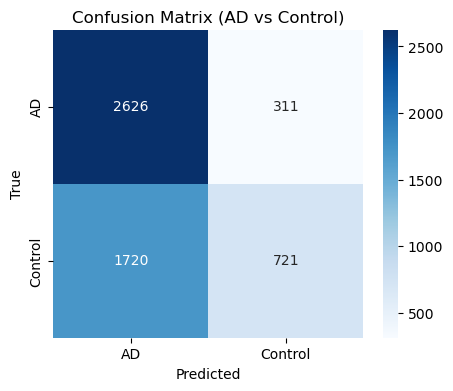

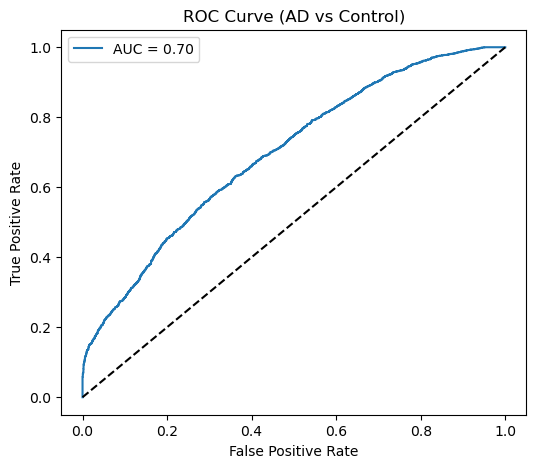

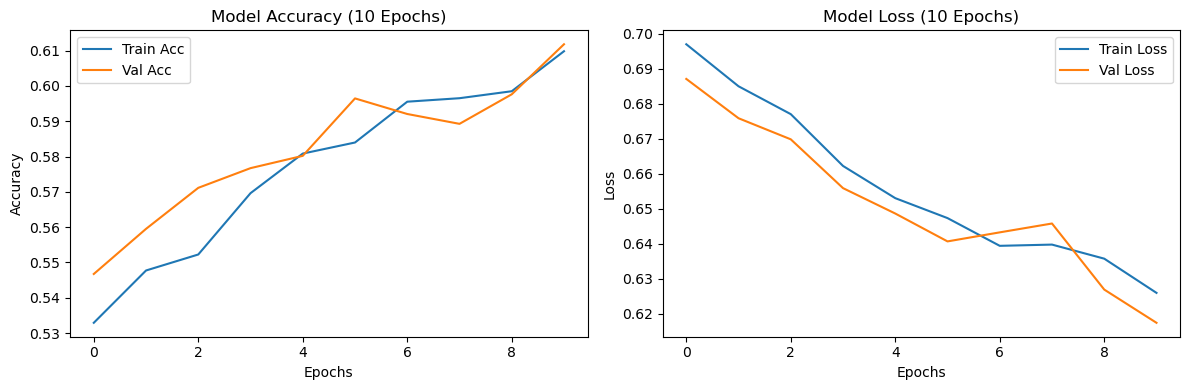


Classification Report:
              precision    recall  f1-score   support

          AD       0.60      0.89      0.72      2937
     Control       0.70      0.30      0.42      2441

    accuracy                           0.62      5378
   macro avg       0.65      0.59      0.57      5378
weighted avg       0.65      0.62      0.58      5378



In [8]:
import os
import multiprocessing
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Bidirectional, LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

# ============================================================
# === OPTIMIZE CPU USAGE =====================================
# ============================================================

num_cores = multiprocessing.cpu_count()
print(f"🧠 Detected {num_cores} CPU cores")

tf.config.threading.set_intra_op_parallelism_threads(num_cores)
tf.config.threading.set_inter_op_parallelism_threads(num_cores)

# Optional: Force CPU-only (uncomment if you want CPU-only)
# tf.config.set_visible_devices([], 'GPU')

# ============================================================
# === PREPARE DATA (Memory-Safe + Normalized) ================
# ============================================================

print("EEG Data Shape:", X.shape)
print("Labels Shape:", y.shape)

# ✅ Convert to smaller dtype to save memory
X = X.astype('float32')
y = y.astype('int32')

# ✅ Normalize in-place (no large memory copies)
X_mean = X.mean(axis=1, keepdims=True)
X_std = X.std(axis=1, keepdims=True) + 1e-6
X -= X_mean
X /= X_std

# ✅ Split dataset into train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"✅ Training shape: {X_train.shape}, Testing shape: {X_test.shape}")
print(f"✅ Data dtype: {X_train.dtype}")

# ============================================================
# === BUILD & TRAIN BILSTM MODEL =============================
# ============================================================

time_steps, channels = X_train.shape[1], X_train.shape[2]

model = Sequential([
    Bidirectional(LSTM(128, return_sequences=True, dropout=0.3), input_shape=(time_steps, channels)),
    BatchNormalization(),
    Bidirectional(LSTM(64, dropout=0.3)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')  # ✅ Binary output (AD vs Control)
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# ✅ Early stopping with lower patience since epochs=10
es = EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True)

print("🚀 Starting Training using all CPU cores...")

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=10,              # ✅ Reduced to 10 epochs
    batch_size=64,
    callbacks=[es],
    verbose=1
)

# ============================================================
# === EVALUATION & VISUALIZATION =============================
# ============================================================

test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"\n✅ Test Accuracy: {test_acc:.3f}")

# === PREDICTIONS ===
y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype(int)
y_true = y_test  # Binary (0 or 1)

# === CONFUSION MATRIX ===
cm = confusion_matrix(y_true, y_pred_classes)
labels = ['AD', 'Control']

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix (AD vs Control)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# === ROC CURVE ===
fpr, tpr, _ = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (AD vs Control)")
plt.legend()
plt.show()

# === TRAINING CURVES ===
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Model Accuracy (10 Epochs)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Model Loss (10 Epochs)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# === CLASSIFICATION REPORT ===
print("\nClassification Report:")
print(classification_report(y_true, y_pred_classes, target_names=labels))
